<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Anomaly Detection = Spotting what does not look normal
#### In this file I walk through how I detect unusual examples with a **Gaussian (normal) distribution**.

The scenario from the course: I run a cluster of servers and measure two things per server - **throughput** (mb/s) and **latency** (ms). Almost all servers behave normally. I want to automatically flag the few that do not, *without* many examples of what "broken" looks like.

Idea: learn what normal looks like -> $p(x)$ = how likely is this server's behavior? -> if $p(x) < \varepsilon$, flag it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The data
I generate it with NumPy (the lab ships a file). Normal servers come from a Gaussian; I add a handful of strange ones. Notice the split used in practice:
- **Training set** - unlabeled, assumed to be (almost all) normal.
- **Cross-validation set** - has a few labeled anomalies (`y_val = 1`) so I can *tune* the threshold.

train: (300, 2) | val: (108, 2) | anomalies in val: 8


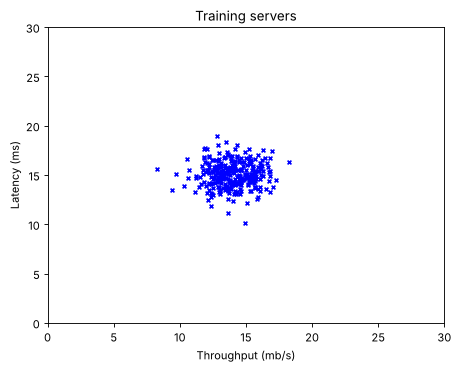

In [2]:
rng = np.random.default_rng(0)
X_train = rng.normal([14.1, 15.0], [1.5, 1.3], size=(300, 2))             # normal servers (unlabeled)
X_val_norm = rng.normal([14.1, 15.0], [1.5, 1.3], size=(100, 2))
X_val_anom = np.array([[8.5, 11.0], [20.5, 18.9], [10.0, 20.0], [18.0, 10.5], [7.0, 17.0],
                       [21.0, 14.0], [13.0, 6.5], [15.0, 23.0]])           # hand-made weird servers
X_val = np.vstack([X_val_norm, X_val_anom])
y_val = np.hstack([np.zeros(len(X_val_norm)), np.ones(len(X_val_anom))])
print("train:", X_train.shape, "| val:", X_val.shape, "| anomalies in val:", int(y_val.sum()))

plt.scatter(X_train[:, 0], X_train[:, 1], marker="x", c="b", s=12)
plt.xlabel("Throughput (mb/s)"); plt.ylabel("Latency (ms)"); plt.title("Training servers"); plt.axis([0, 30, 0, 30])
plt.show()

## Step 1 - Estimate the Gaussian from the training data
For each feature $j$ I estimate its mean and variance:

$$\mu_j = \frac{1}{m}\sum_i x_j^{(i)} \qquad \sigma_j^2 = \frac{1}{m}\sum_i (x_j^{(i)} - \mu_j)^2$$

(divide by $m$, not $m-1$, as in the course - for large $m$ it makes no practical difference).

In [3]:
def estimate_gaussian(X):
    mu = X.mean(axis=0)
    var = ((X - mu) ** 2).mean(axis=0)
    return mu, var

mu, var = estimate_gaussian(X_train)
print("mu :", mu.round(2))
print("var:", var.round(2))

mu : [13.97 15.05]
var: [2.26 1.65]


## Step 2 - Probability of an example
Assuming the features are independent, $p(x) = \prod_j p(x_j;\mu_j,\sigma_j^2)$, with

$$p(x_j) = \frac{1}{\sqrt{2\pi\sigma_j^2}}\exp\!\left(-\frac{(x_j-\mu_j)^2}{2\sigma_j^2}\right)$$

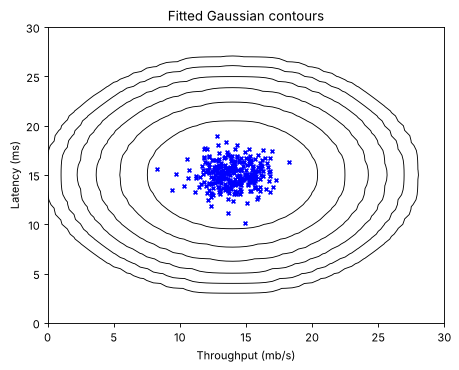

In [4]:
def multivariate_gaussian(X, mu, var):
    p = np.exp(-((X - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)
    return p.prod(axis=1)

def visualize_fit(X, mu, var):
    xs = np.arange(0, 35.5, 0.5)
    X1, X2 = np.meshgrid(xs, xs)
    Z = multivariate_gaussian(np.stack([X1.ravel(), X2.ravel()], axis=1), mu, var).reshape(X1.shape)
    plt.scatter(X[:, 0], X[:, 1], marker="x", c="b", s=12)
    plt.contour(X1, X2, Z, levels=10.0 ** np.arange(-20, -2, 3), colors="k", linewidths=0.8)
    plt.xlabel("Throughput (mb/s)"); plt.ylabel("Latency (ms)"); plt.title("Fitted Gaussian contours"); plt.axis([0, 30, 0, 30])

visualize_fit(X_train, mu, var)
plt.show()

## Step 3 - Choose the threshold $\varepsilon$ with F1
Anomalies are rare (here ~7% of the validation set), so **accuracy is useless** - a model that says "everything is normal" would be 93% accurate and catch nothing. I use the **F1 score** instead:

$$prec = \frac{tp}{tp+fp} \qquad rec = \frac{tp}{tp+fn} \qquad F_1 = \frac{2\cdot prec\cdot rec}{prec+rec}$$

I try many values of $\varepsilon$ on the validation set and keep the one with the best F1. (The course code steps through $\varepsilon$ in equal increments; I space the candidates on a log scale instead, because $p(x)$ can differ by many orders of magnitude - with equal steps the 11-feature example below gets a poor F1.)

In [5]:
def select_threshold(y_val, p_val):
    best_epsilon, best_F1 = 0, 0
    # log-spaced candidates: p(x) can span many orders of magnitude, so equal steps would skip all the small values
    for epsilon in np.geomspace(max(p_val.min(), 1e-300), p_val.max(), 1000):
        pred = p_val < epsilon                      # low probability -> anomaly
        tp = np.sum(pred & (y_val == 1))
        fp = np.sum(pred & (y_val == 0))
        fn = np.sum(~pred & (y_val == 1))
        if tp == 0:
            continue
        prec, rec = tp / (tp + fp), tp / (tp + fn)
        F1 = 2 * prec * rec / (prec + rec)
        if F1 > best_F1:
            best_F1, best_epsilon = F1, epsilon
    return best_epsilon, best_F1

p_train = multivariate_gaussian(X_train, mu, var)
p_val = multivariate_gaussian(X_val, mu, var)
epsilon, F1 = select_threshold(y_val, p_val)
print(f"Best epsilon: {epsilon:.3e} | F1 on validation: {F1:.3f}")

Best epsilon: 4.306e-06 | F1 on validation: 1.000


flagged in training set: 0 of 300


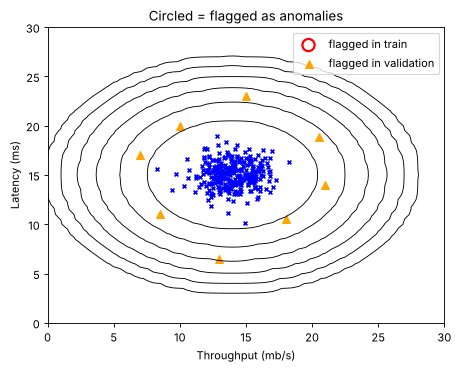

In [6]:
outliers = p_train < epsilon
visualize_fit(X_train, mu, var)
plt.scatter(X_train[outliers, 0], X_train[outliers, 1], s=120, facecolors="none", edgecolors="r", linewidths=2, label="flagged in train")
va = X_val[p_val < epsilon]
plt.scatter(va[:, 0], va[:, 1], marker="^", c="orange", s=50, label="flagged in validation")
plt.legend(); plt.title("Circled = flagged as anomalies"); plt.show()
print("flagged in training set:", int(outliers.sum()), "of", len(X_train))

## A higher-dimensional dataset
The same code works unchanged for 11 features - the plot is gone, but the maths is identical. This is where anomaly detection earns its keep: I can't see 11 dimensions, but $p(x)$ still gives one number per example.

In [7]:
rng = np.random.default_rng(5)
mean11 = rng.uniform(5, 20, 11); std11 = rng.uniform(0.8, 2.0, 11)
X_tr11 = rng.normal(mean11, std11, size=(1000, 11))
X_v_n = rng.normal(mean11, std11, size=(300, 11))
shift = rng.choice([-1, 1], size=(10, 11)) * (rng.random((10, 11)) < 0.4) * 4 * std11       # ~4 of 11 features pushed 4 std away
X_v_a = rng.normal(mean11, std11, size=(10, 11)) + shift
X_v11 = np.vstack([X_v_n, X_v_a]); y_v11 = np.hstack([np.zeros(300), np.ones(10)])

mu11, var11 = estimate_gaussian(X_tr11)
eps11, F1_11 = select_threshold(y_v11, multivariate_gaussian(X_v11, mu11, var11))
print(f"Best epsilon: {eps11:.3e} | F1: {F1_11:.3f}")
print("anomalies found in training set:", int((multivariate_gaussian(X_tr11, mu11, var11) < eps11).sum()), "of 1000")

Best epsilon: 1.744e-16 | F1: 1.000
anomalies found in training set: 0 of 1000


## Check the Gaussian assumption
The method assumes each feature looks like a bell curve. If a feature is skewed (e.g. a latency with a long tail), I can often fix it with a transform such as $\log(x + c)$ or $\sqrt{x}$. I always look at a histogram first.

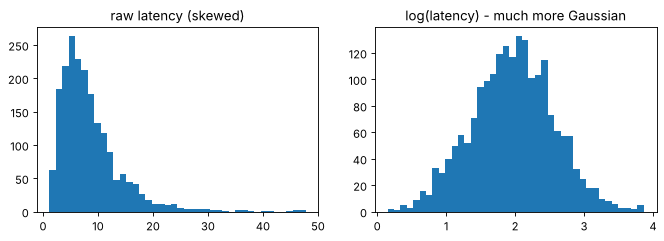

In [8]:
rng = np.random.default_rng(2)
skewed = rng.lognormal(2.0, 0.6, 2000)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(skewed, bins=40); ax[0].set_title("raw latency (skewed)")
ax[1].hist(np.log(skewed), bins=40); ax[1].set_title("log(latency) - much more Gaussian")
plt.show()

## The scikit-learn version
scikit-learn does not have my exact "Gaussian + threshold" model, but it has other anomaly detectors that need no labels. **Isolation Forest** isolates points with random splits: anomalies are isolated in fewer splits.

In [9]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score

iso = IsolationForest(contamination=0.05, random_state=0).fit(X_train)
pred = (iso.predict(X_val) == -1).astype(int)             # sklearn returns -1 for anomalies
print("Isolation Forest F1 on validation:", round(f1_score(y_val, pred), 3))
print("My Gaussian model F1 on validation :", round(F1, 3))

Isolation Forest F1 on validation: 0.727
My Gaussian model F1 on validation : 1.0


## Anomaly detection vs supervised learning - when to use which
- **Anomaly detection**: very few positive examples, and future anomalies may look *different* from past ones (new kinds of fraud, new failure modes).
- **Supervised learning**: lots of positive examples and future positives look like past ones (e.g. spam).

## Drawbacks / things to remember
- Treats features as **independent** - it misses an anomaly that is only unusual in the *combination* (e.g. high CPU is normal, low traffic is normal, but high CPU *with* low traffic is not). Fix: create a combined feature such as CPU/traffic, or use the full multivariate Gaussian with a covariance matrix.
- **Needs roughly Gaussian features** - check histograms and transform.
- $\varepsilon$ must be tuned on **labeled validation data**; with too few anomalies the F1 estimate is noisy.
- Rare-event problem: always use precision / recall / F1, never plain accuracy.